In [11]:
import pandas as pd

df = pd.read_csv('../G2CP/results/calculated_new_CPI_unipert_similarity.csv')
df = df.rename(columns={
    'UniPert similarity': 'score'
})

In [3]:
len(df['target'].value_counts()), len(df['compound'].value_counts()), len(df)

(3132, 39478, 123645096)

In [14]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import fontManager, FontProperties
import seaborn as sns

font_path = "../Helvetica.ttf"
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()

sns.set_theme(
    style="ticks",
    context="paper",
    font_scale=1.1,
    rc={
        "axes.linewidth": 0.5,
        "axes.edgecolor": "black",
        "axes.labelsize": 9,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "xtick.major.size": 2,
        "ytick.major.size": 2,
        "figure.dpi": 150,
        "savefig.dpi": 600,
        "axes.facecolor": (0, 0, 0, 0),
    }
)

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name]   
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42
plt.rcParams["legend.facecolor"] = "white"

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

top_fracs = [0.005, 0.01, 0.05, 0.10]   # 0.5%, 1%, 5%, 10%
top_labels = ['0.5%', '1%', '5%', '10%']

efs_per_frac = {f: [] for f in top_fracs}

n_trues = []
targets = []
compounds = set()
for tgt, sub in tqdm(df.groupby('target', sort=False)):
    y_true = sub['Label'].values.astype(int)
    y_score = sub['score'].values.astype(float)

    n_actives_total = y_true.sum()
    if n_actives_total == 0:
        continue 

    n = len(y_true)
    n_trues.append(n_actives_total)
    order = np.argsort(-y_score)  
    y_sorted = y_true[order]

    p_all = n_actives_total / n

    cumsum_hits = np.cumsum(y_sorted)

    for frac in top_fracs:
        k = int(round(n * frac))
        if k < 1:
            continue

        hits_top = cumsum_hits[k-1]
        ef = (hits_top / k) / p_all
        efs_per_frac[frac].append(ef)

    targets.append(tgt)
    compounds.update(sub['compound'].unique())

print(f"Total targets: {len(targets)}")
print(f"Total compounds: {len(compounds)}")
print(f"Total positives: {sum(n_trues)}")
mean_efs, std_efs = [], []
for frac in top_fracs:
    vals = np.array(efs_per_frac[frac])
    mean_efs.append(vals.mean())
    std_efs.append(vals.std(ddof=1))
    print(f"Top {frac*100:.1f}%: mean EF={vals.mean():.2f}, "
          f"median EF={np.median(vals):.2f}")

100%|██████████| 1216/1216 [00:15<00:00, 78.98it/s] 


Total targets: 1216
Total compounds: 37820
Total positives: 81650
Top 0.5%: mean EF=19.19, median EF=8.00
Top 1.0%: mean EF=12.54, median EF=6.67
Top 5.0%: mean EF=4.88, median EF=3.80
Top 10.0%: mean EF=3.28, median EF=2.96


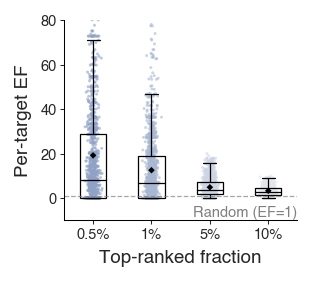

In [15]:
import matplotlib.pyplot as plt
import numpy as np

top_fracs = [0.005, 0.01, 0.05, 0.10]
top_labels = ['0.5%', '1%', '5%', '10%']

data = [np.array(efs_per_frac[frac]) for frac in top_fracs]

fig, ax = plt.subplots(figsize=(2.2, 2))
positions = np.arange(1, len(top_fracs) + 1)
bp = ax.boxplot(
    data,
    positions=positions,
    showfliers=False,     
    patch_artist=True     
)

for box in bp['boxes']:
    box.set_facecolor('none')
    box.set_edgecolor('black')
    box.set_linewidth(0.6)

for whisker in bp['whiskers']:
    whisker.set_color('black')
    whisker.set_linewidth(0.6)

for cap in bp['caps']:
    cap.set_color('black')
    cap.set_linewidth(0.6)

for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(0.6)

colors = ['#8FA2C6', '#A8B7D2', '#CDD4E4', '#E4E6ED']
for i, vals in enumerate(data, start=1):
    x_jitter = np.random.normal(loc=i, scale=0.05, size=len(vals))
    ax.scatter(
        x_jitter, vals,
        s=2, 
        alpha=0.6,
        edgecolors='none',
        color=colors[i-1]
    )

# random baseline: EF = 1
ax.axhline(
    y=1.0,
    color='gray',
    linestyle='--',
    linewidth=0.6,
    alpha=0.7
)
ax.text(
    positions[-1] + 0.5, -9.5,
    "Random (EF=1)",
    ha='right', va='bottom',
    fontsize=7, color='gray'
)

means = [np.mean(vals) for vals in data]

for x_pos, m in zip(positions, means):
    ax.scatter(
        x_pos, m,
        s=5,
        marker='D',   
        facecolors='black',
        edgecolors='none',
        zorder=3
    )

all_vals = np.concatenate(data)
y_max = np.percentile(all_vals, 98) 
ax.set_ylim(-10, 80)

ax.set_xlabel("Top-ranked fraction", labelpad=4, fontsize=9)
ax.set_ylabel("Per-target EF", labelpad=4, fontsize=9)

ax.set_xticks(positions)
ax.set_xticklabels(top_labels, fontsize=8)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(direction='out', length=2, width=0.5, pad=1.5, labelsize=7)

plt.tight_layout()
plt.show()